<a href="https://colab.research.google.com/github/SamuelSousaFerreira/time-series-with-pyTorch/blob/main/5_simple_neural_arqchiteture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =============================================================================
# Chapter 5: Simple Neural Architecture
# =============================================================================
# Code companion for Chapter 5
# Covers: perceptrons, artificial neurons, activation functions, feedforward
#         neural networks (FFN), window embeddings, early stopping
# =============================================================================

import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn
from torch.optim import SGD, Adam

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# =============================================================================
# Setup: palette, rcParams, CFG
# =============================================================================

custom_palette = ["#000000", "#0072B2", "#D55E00", "#009E73",
                  "#CC79A7", "#56B4E9", "#E69F00"]
line_styles = ['-', '--', '-.', ':']

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Source Sans Pro', 'Arial']
plt.rcParams['font.size'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['axes.titlesize'] = 18

class CFG:
    data_folder = Path.cwd() /  "Data" # "Time-Series-with-PyTorch" /
    img_dim1 = 12
    img_dim2 = 6
    fontsize = 18

plt.rcParams.update({'figure.figsize': (CFG.img_dim1, CFG.img_dim2)})


# =============================================================================
# Helper: error metrics
# =============================================================================

def mae(actual, predicted):
    return np.mean(np.abs(predicted - actual))

def mse(actual, predicted):
    return np.mean(np.square(predicted - actual))

def rmse(actual, predicted):
    return np.sqrt(np.mean(np.square(predicted - actual)))

def mape(actual, predicted):
    mask = actual != 0
    return np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100

def smape(actual, predicted):
    return 100 / len(actual) * np.sum(
        2 * np.abs(predicted - actual) / (np.abs(actual) + np.abs(predicted)))

In [ ]:
# Cria a pasta Data se ela não existir
import os
os.makedirs('Data', exist_ok=True)

# Baixa o arquivo passengers.csv diretamente do repositório do GitHub
!wget -P Data/ https://raw.githubusercontent.com/PacktPublishing/Time-Series-with-PyTorch/main/Data/passengers.csv

--2026-11-08 19:00:22--  https://raw.githubusercontent.com/PacktPublishing/Time-Series-with-PyTorch/main/Data/passengers.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1744 (1.7K) [text/plain]
Saving to: ‘Data/passengers.csv.3’

passengers.csv.3    100%[===================>]   1.70K  --.-KB/s    in 0s      

2026-11-08 19:00:23 (22.6 MB/s) - ‘Data/passengers.csv.3’ saved [1744/1744]



In [ ]:
from torch.utils.data import DataLoader, TensorDataset

# Stochastic Gradient Descent (SGD)

In [ ]:
class true_perceptron:
    def __init__(self, input_dim, learning_rate=0.1):
        # Inicializa os pesos com zero. O tamanho é a dimensão de entrada + 1 para incluir o bias.
        # self.weights[0] será o bias (viés) e o restante serão os pesos das características (features).
        self.weights = np.zeros(input_dim + 1)
        self.learning_rate = learning_rate

    def predict(self, inputs):
        # Função de ativação degrau unitário (Unit Step Function)
        # Calcula o produto escalar (dot product) dos pesos e das entradas e soma o bias (self.weights[0])
        summation = np.dot(inputs, self.weights[1:]) + self.weights[0]
        # Se a soma for maior que zero, ativa como 1, caso contrário retorna 0
        return 1 if summation > 0 else 0

    def train(self, training_inputs, labels, epochs=20):
        # Loop para treinar o perceptron durante o número especificado de épocas
        for _ in range(epochs):
            # Percorre cada exemplo de treino e seu respectivo rótulo esperado (label)
            for inputs, label in zip(training_inputs, labels):
                # Realiza a predição para a entrada atual
                prediction = self.predict(inputs)
                # Atualiza os pesos das características com base no erro (rótulo - predição)
                self.weights[1:] += self.learning_rate * (label - prediction) * inputs
                # Atualiza o peso do bias individualmente
                self.weights[0] += self.learning_rate * ( label - prediction)

In [ ]:
# Criando as entradas de treinamento para simular a porta lógica 'AND'
training_inputs = []
training_inputs.append(np.array([1, 1]))  # Entrada 1: Verdadeiro e Verdadeiro
training_inputs.append(np.array([1, 0]))  # Entrada 2: Verdadeiro e Falso
training_inputs.append(np.array([0, 1]))  # Entrada 3: Falso e Verdadeiro
training_inputs.append(np.array([0, 0]))  # Entrada 4: Falso e Falso

# Rótulos de saída esperados para a porta lógica 'AND' (Apenas [1, 1] resulta em 1)
labels = np.array([1, 0, 0, 0])

# Criação de um objeto Perceptron com dimensão de entrada igual a 2 (duas variáveis de entrada)
perceptron = true_perceptron(2)

# Treina o modelo utilizando os dados e rótulos definidos acima
perceptron.train(training_inputs, labels)

# Testando o comportamento do perceptron após o treinamento
# Entrada: [1, 1] -> Saída esperada deve ser 1
inputs = np.array([1, 1])
print("Predição para [1, 1]:", perceptron.predict(inputs))

# Entrada: [0, 1] -> Saída esperada deve ser 0
inputs = np.array([0, 1])
print("Predição para [0, 1]:", perceptron.predict(inputs))

Predição para [1, 1]: 1
Predição para [0, 1]: 0


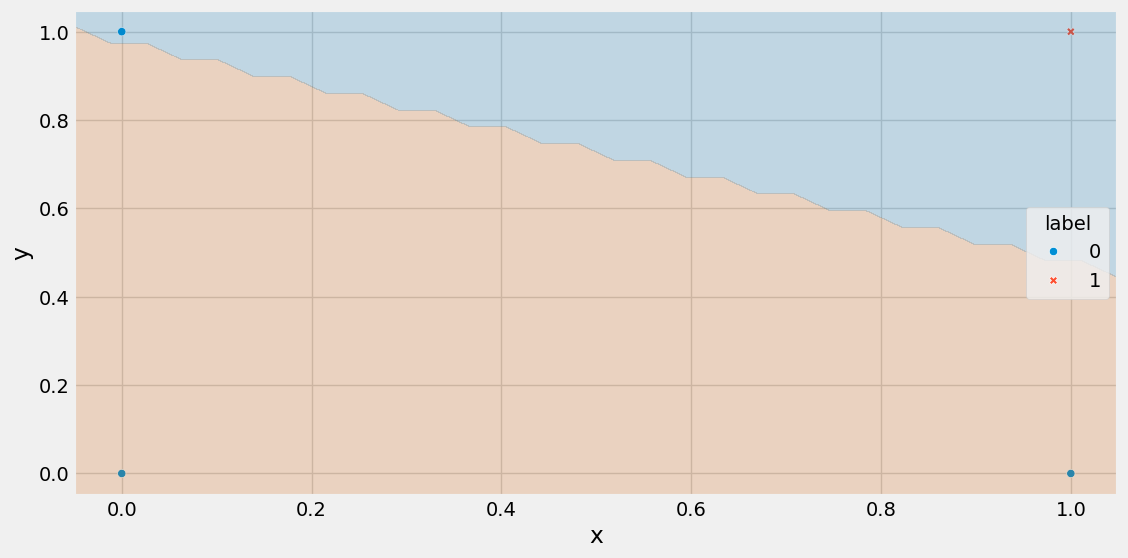

In [ ]:
def plot_decision_boundary(perceptron, inputs, labels):
    # Define o estilo visual clássico do site FiveThirtyEight
    plt.style.use('fivethirtyeight')

    # Cria um DataFrame unindo as entradas (coordenadas x e y) e os rótulos reais para plotagem
    df = pd.DataFrame(np.concatenate(
        [inputs, labels.reshape(-1,1)], axis=1
    ), columns=['x', 'y', 'label'])

    # Plota os pontos reais de treino diferenciados por cor e estilo de marcador
    sns.scatterplot(x='x', y='y', hue='label', style='label', data=df)

    # Obtém os limites dos eixos atuais do gráfico para gerar o plano de fundo classificatório
    xmin, xmax = plt.xlim()
    ymin, ymax = plt.ylim()

    # Cria uma malha (grid) cobrindo todo o espaço do gráfico para avaliar as predições do perceptron
    xs = np.linspace(xmin, xmax, 30)
    ys = np.linspace(ymin, ymax, 30)
    Y, X = np.meshgrid(ys, xs)

    # Calcula as predições de classificação para cada ponto da grade de pixels gerada
    predictions = np.array(
        [perceptron.predict(np.array([x, y]))
        for x, y in zip(np.ravel(X), np.ravel(Y))]
    )
    predictions = predictions.reshape(X.shape)

    # Desenha as áreas coloridas que delimitam a região de cada classe (fronteira de decisão)
    ax = plt.gca()
    ax.contourf(X, Y, predictions,
                colors=['#D55E00', '#0072B2'],
                alpha=0.2, levels=range(-1, 2))
    plt.show()

# Executa a função passando o perceptron treinado e os dados da porta lógica AND
plot_decision_boundary(perceptron, training_inputs, labels)

# Continuous input & output perceptron

In [ ]:
class Diff_Perceptron:
  # O inicializador cria o perceptron definindo seu tamanho e suas configurações iniciais
  def __init__(self, input_dim, learning_rate=0.1, activation_function = lambda x:x):
    # Cria uma lista de pesos zerados. O tamanho é o número de entradas + 1 devido ao viés w*x + b
    self.weights = np.zeros(input_dim + 1)
    # Guarda a taxa de aprendizado (o tamanho do passo que o modelo dá ao aprender)
    self.learning_rate = learning_rate
    # Guarda a função de ativação escolhida (se nenhuma for passada, ele apenas devolve o próprio número)
    self.activation_function = activation_function

  # O método predict calcula a resposta (palpite) do neurônio para um conjunto de entradas
  def predict (self, inputs):
    # Faz a soma ponderada: multiplica cada entrada pelo seu peso correspondente e soma com o viés (bias)
    summation = np.dot(inputs, self.weights[1:]) + self.weights[0]
    # Passa o resultado da soma pela função de ativação para gerar a previsão final
    return self.activation_function(summation)

  # O método train ajusta os pesos do neurônio para que ele aprenda com os erros dos dados de treino
  def train(self, training_inputs, labels, epochs=20):
    # Repete o processo de treino pelo número de épocas (ciclos completos de treino)
    for _ in range(epochs):
      # Analisa um exemplo de cada vez (entradas e a resposta correta esperada)
      for inputs, label in zip(training_inputs, labels):
        # Calcula a soma ponderada atual das entradas usando os pesos correspondentes e o viés
        summation = np.dot(inputs, self.weights[1:]) + self.weights[0]
        # Passa essa soma pela função de ativação para obter o palpite atual do modelo
        prediction = self.activation_function(summation)
        # Calcula o erro cometida: a diferença entre a resposta correta e a prevista pelo modelo
        error = label - prediction
        # Ajusta os pesos das características com base no erro calculado e na taxa de aprendizado
        self.weights[1:] += self.learning_rate * error * inputs
        # Ajusta o valor do viés (bias) de forma independente baseado também no erro
        self.weights[0] += self.learning_rate * error

In [ ]:
# Gerando dados sintéticos aleatórios para treino
np.random.seed(42)
# Criando 100 pontos de dados aleatórios entre -2 e 2 para o eixo X

x_train = np.random.uniform(-2, 2, 100)
# Remodelando o array para o formato de matriz coluna exigido pelo Perceptron
x_train_reshaped = x_train.reshape(-1, 1)

# Gerando saídas correspondentes com uma função linear mais um pouco de ruído aleatório
y_train = 1.5 * x_train + 0.5 + np.random.normal(0, 0.5, 100)

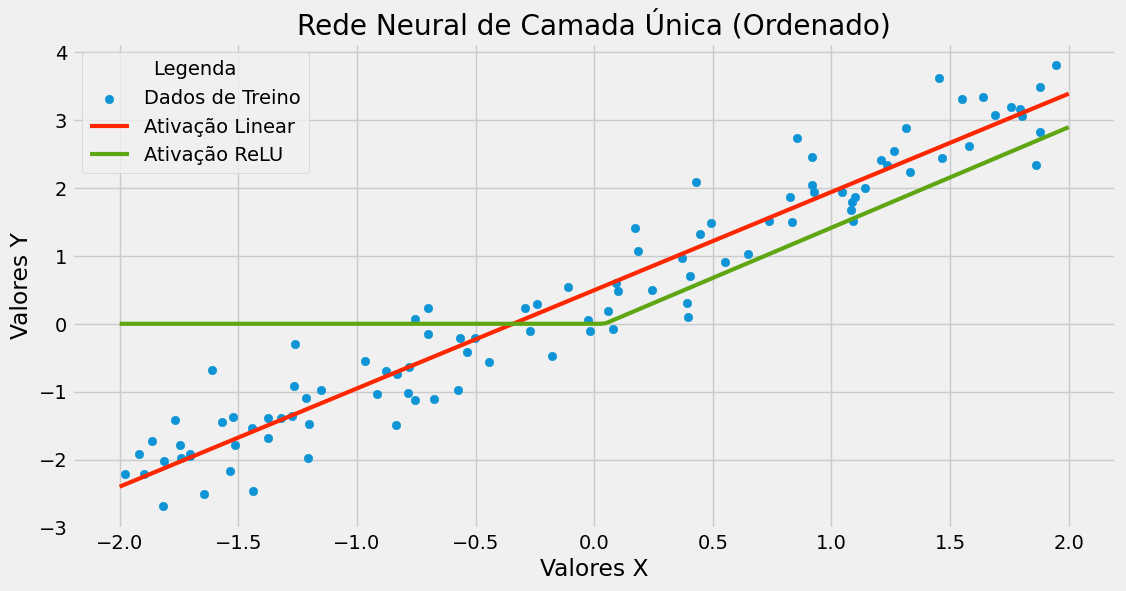

In [ ]:
# Para desenhar as linhas corretamente, precisamos de pontos ordenados de X
x_plot = np.linspace(-2, 2, 200)
x_plot_reshaped = x_plot.reshape(-1, 1)

# Scatterplot original com os dados de treino
plt.scatter(x_train, y_train, color='#0F95D7', label='Dados de Treino')

# Predições ordenadas para ativação Linear
y_pred_linear_sorted = [nn_linear.predict(np.array([x])) for x in x_plot]
plt.plot(x_plot, y_pred_linear_sorted, color='#FF2700', linewidth=3, label='Ativação Linear')

# Predições ordenadas para ativação ReLU
y_pred_relu_sorted = [nn_relu.predict(np.array([x])) for x in x_plot]
plt.plot(x_plot, y_pred_relu_sorted, color='#5FA613', linewidth=3, label='Ativação ReLU')

plt.xlabel('Valores X')
plt.ylabel('Valores Y')
plt.title('Rede Neural de Camada Única (Ordenado)')
plt.legend(title='Legenda', loc='best')
plt.show();

In [ ]:
# Set seed
np.random.seed(42)
# Load dataset
data = pd.read_csv(CFG.data_folder / 'passengers.csv')
# Preprocess data
# Convert 'date' to datetime
data['date'] = pd.to_datetime(data['date'])
# Set 'date' as the index
data.set_index('date', inplace=True)
data.head()


,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [ ]:
# Sequential split
train_size = int(len(data) * 0.6)
val_size = int(len(data) * 0.2)
train, val, test = data[:train_size], data[train_size:train_size + val_size], data[train_size + val_size:]


In [ ]:
# Scaling: Min-Max
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
test_scaled = scaler.transform(test)

In [ ]:
# Prepare data with lags
def prepare_data(data, max_lag = 12):
  dataX, dataY = [], []
  for i in range(max_lag, len(data) - 1):
    dataX.append(data[i - max_lag:i, 0])
    dataY.append(data[i,0])
  return np.array(dataX), np.array(dataY)

lags = 12
trainX, trainY = prepare_data(train_scaled, lags)
valX, valY = prepare_data(val_scaled, lags)
testX, testY = prepare_data(test_scaled, lags)

In [ ]:
# Initialize model with ReLU activation function
def relu(x):
    return np.maximum(0, x)

In [ ]:
diff_perceptron = Diff_Perceptron(input_dim= lags, learning_rate=0.001, activation_function=relu)

In [ ]:
# Define o menor erro de validação encontrado como infinito no início
best_val_loss = float('inf')

# Define o limite de paciência (10 épocas sem melhora) e o contador de espera
patience, wait = 10, 0

# Inicia o ciclo de treinamento para rodar por até 200 épocas
for epoch in range(200):
    # Treina o perceptron por apenas 1 época usando os dados de treino modificados por lag
    diff_perceptron.train(trainX, trainY, epochs=1)

    # Gera as previsões do modelo utilizando os dados de validação
    val_predictions = diff_perceptron.predict(valX)

    # Calcula o erro quadrático médio (MSE) entre as respostas reais e as previstas pelo modelo
    val_loss = mean_squared_error(valY, val_predictions)

    # Verifica se o erro atual de validação é menor que o melhor erro registrado até agora
    if val_loss < best_val_loss:
        # Atualiza o melhor erro registrado com o novo valor mais baixo
        best_val_loss = val_loss
        # Reinicia o contador de paciência, pois o modelo acabou de apresentar melhora
        wait = 0
    else:
        # Caso o erro não tenha melhorado, incrementa 1 no contador de espera
        wait += 1
        # Se o contador atingir o limite de paciência definido (10 épocas sem melhora)
        if wait >= patience:
            # Exibe uma mensagem informando em qual época o treinamento foi interrompido
            print(f"Early stopping on epoch {epoch}")
            # Interrompe o loop de treinamento
            break

In [ ]:
# Gera as predições para os dados de teste usando o perceptron treinado
scaled_predictions = diff_perceptron.predict(testX)

# Gera as predições para os dados de treino (dentro da amostra)
train_predictions = diff_perceptron.predict(trainX)

# Transforma as predições de treino de volta para a escala original de passageiros (revertendo o Min-Max)
unscaled_train_predictions = scaler.inverse_transform(train_predictions.reshape(-1, 1))

# Cria o índice de datas correto para as predições de treino, considerando o deslocamento dos lags
train_pred_index = data.index[lags:lags + len(unscaled_train_predictions)]

# Gera as predições para os dados de validação
val_predictions_plot = diff_perceptron.predict(valX)

# Transforma as predições de validação de volta para a escala original de passageiros
unscaled_val_predictions = scaler.inverse_transform(val_predictions_plot.reshape(-1, 1))

# Cria o índice de datas correto para as predições de validação, alinhando após o final do treino
val_pred_index = data.index[train_size + lags:train_size + lags + len(unscaled_val_predictions)]

In [ ]:
# Inverse Scaling
unscaled_predictions = scaler.inverse_transform(
    scaled_predictions.reshape(-1, 1))
test_index = data.index[-len(unscaled_predictions):]

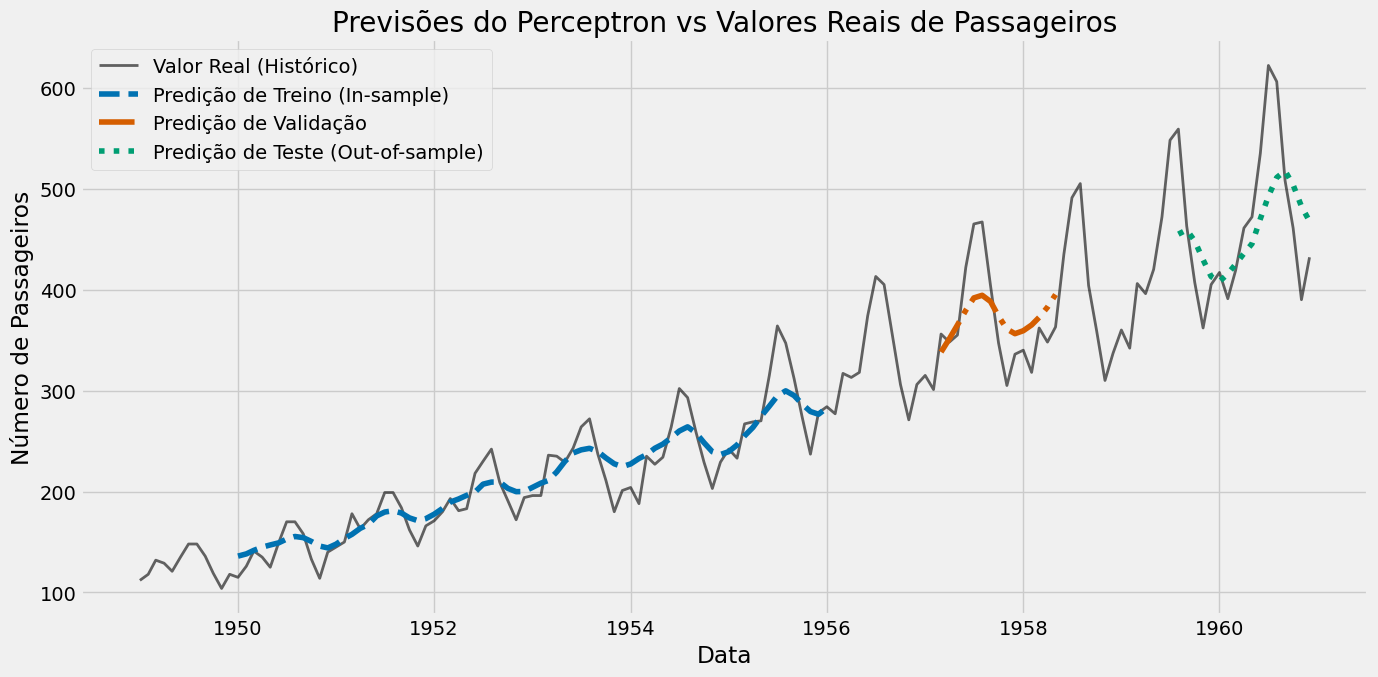

In [ ]:
# Define o estilo visual clássico
plt.style.use('fivethirtyeight')
plt.figure(figsize=(14, 7))

# Plota a série temporal com os dados reais de passageiros
plt.plot(data.index, data['passengers'], color='#000000', label='Valor Real (Histórico)', alpha=0.6, linewidth=2)

# Plota as previsões dentro da amostra (Treino)
plt.plot(train_pred_index, unscaled_train_predictions, color='#0072B2', label='Predição de Treino (In-sample)', linestyle='--')

# Plota as previsões de validação
plt.plot(val_pred_index, unscaled_val_predictions, color='#D55E00', label='Predição de Validação', linestyle='-.')

# Plota as previsões para os dados de teste futuros
plt.plot(test_index, unscaled_predictions, color='#009E73', label='Predição de Teste (Out-of-sample)', linestyle=':')

# Configurações de títulos e rótulos do gráfico
plt.title('Previsões do Perceptron vs Valores Reais de Passageiros')
plt.xlabel('Data')
plt.ylabel('Número de Passageiros')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Obtendo os valores reais do conjunto de teste na escala original de passageiros
# testY contém os alvos escalados; revertemos para a escala original
actual_test = scaler.inverse_transform(testY.reshape(-1, 1)).flatten()
predicted_test = unscaled_predictions.flatten()

# Definição manual do WAPE (Weighted Absolute Percentage Error)
def wape(actual, predicted):
    return (np.sum(np.abs(actual - predicted)) / np.sum(actual)) * 100

# Calculando cada uma das métricas usando as funções auxiliares existentes e a nova do WAPE
metrics_data = {
    'Métrica': ['MAE', 'MSE', 'RMSE', 'MAPE (%)', 'sMAPE (%)', 'WAPE (%)'],
    'Valor': [
        mae(actual_test, predicted_test),
        mse(actual_test, predicted_test),
        rmse(actual_test, predicted_test),
        mape(actual_test, predicted_test),
        smape(actual_test, predicted_test),
        wape(actual_test, predicted_test)
    ]
}

# Estruturando os dados em uma tabela (DataFrame) e exibindo
df_metrics = pd.DataFrame(metrics_data)
display(df_metrics)

,Métrica,Valor
0,MAE,41.134748
1,MSE,3066.113265
2,RMSE,55.372496
3,MAPE (%),8.295823
4,sMAPE (%),8.486111
5,WAPE (%),8.712817


In [ ]:
# Criando um dicionário com a explicação simples de cada métrica
explicacoes = [
    "Erro Médio Absoluto: Mostra, em média, o quão distante as previsões estão dos valores reais (na mesma unidade original).",
    "Erro Quadrático Médio: Penaliza erros maiores ao elevar as diferenças ao quadrado (útil para identificar grandes desvios).",
    "Raiz do Erro Quadrático Médio: A raiz do MSE, trazendo a penalização de grandes erros de volta para a escala original de passageiros.",
    "Erro Percentual Absoluto Médio: Mostra o erro médio em porcentagem em relação aos valores reais.",
    "Erro Percentual Absoluto Médio Simétrico: Versão ajustada do MAPE que evita distorções quando os valores reais são muito próximos de zero.",
    "Erro Percentual Absoluto Ponderado: Mede o erro percentual global ponderando o volume total, muito robusto para séries com sazonalidade."
]

# Adicionando a nova coluna de explicações ao nosso DataFrame de métricas
df_metrics_explained = df_metrics.copy()
df_metrics_explained['O que significa?'] = explicacoes

# Exibindo a tabela expandida de forma legível
pd.set_option('display.max_colwidth', None)
display(df_metrics_explained)

,Métrica,Valor,O que significa?
0,MAE,41.134748,"Erro Médio Absoluto: Mostra, em média, o quão distante as previsões estão dos valores reais (na mesma unidade original)."
1,MSE,3066.113265,Erro Quadrático Médio: Penaliza erros maiores ao elevar as diferenças ao quadrado (útil para identificar grandes desvios).
2,RMSE,55.372496,"Raiz do Erro Quadrático Médio: A raiz do MSE, trazendo a penalização de grandes erros de volta para a escala original de passageiros."
3,MAPE (%),8.295823,Erro Percentual Absoluto Médio: Mostra o erro médio em porcentagem em relação aos valores reais.
4,sMAPE (%),8.486111,Erro Percentual Absoluto Médio Simétrico: Versão ajustada do MAPE que evita distorções quando os valores reais são muito próximos de zero.
5,WAPE (%),8.712817,"Erro Percentual Absoluto Ponderado: Mede o erro percentual global ponderando o volume total, muito robusto para séries com sazonalidade."
